2025-07-24 20:36:00.732474: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753389360.940177      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753389361.002078      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1753391290.976100      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1753391290.976786      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability:

Epoch 1/10


I0000 00:00:1753391296.870684      62 service.cc:148] XLA service 0x79a7b4005250 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753391296.872027      62 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1753391296.872053      62 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1753391297.134542      62 cuda_dnn.cc:529] Loaded cuDNN version 90300


  18/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.5321 - loss: 0.6992

I0000 00:00:1753391299.144326      62 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2539/2539 ━━━━━━━━━━━━━━━━━━━━ 31s 11ms/step - accuracy: 0.5255 - loss: 0.6919 - val_accuracy: 0.6033 - val_loss: 0.6762
Epoch 2/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6189 - loss: 0.6531 - val_accuracy: 0.7073 - val_loss: 0.5965
Epoch 3/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6778 - loss: 0.6014 - val_accuracy: 0.7693 - val_loss: 0.5186
Epoch 4/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.6967 - loss: 0.5805 - val_accuracy: 0.7759 - val_loss: 0.5079
Epoch 5/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7033 - loss: 0.5705 - val_accuracy: 0.7190 - val_loss: 0.5614
Epoch 6/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7043 - loss: 0.5678 - val_accuracy: 0.7457 - val_loss: 0.5240
Epoch 7/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7098 - loss: 0.5620 - val_accuracy: 0.7372 - val_loss: 0.5323
Epoch 8/10
2539/2539 ━━━━━━━━━━━━━━━━━━━━ 25s 10ms/step - accuracy: 0.7135 - loss: 0.55

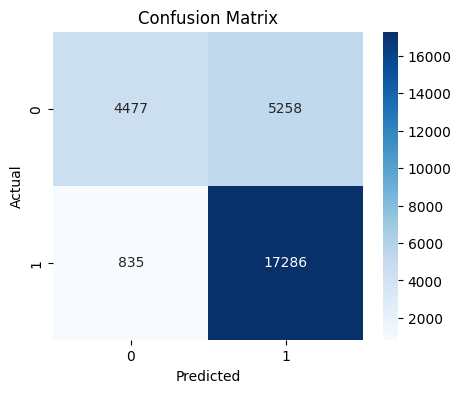


Classification Report:
               precision    recall  f1-score   support

           0     0.8428    0.4599    0.5951      9735
           1     0.7668    0.9539    0.8502     18121

    accuracy                         0.7813     27856
   macro avg     0.8048    0.7069    0.7226     27856
weighted avg     0.7933    0.7813    0.7610     27856

Sensitivity (Recall): 0.9539
Specificity: 0.4599


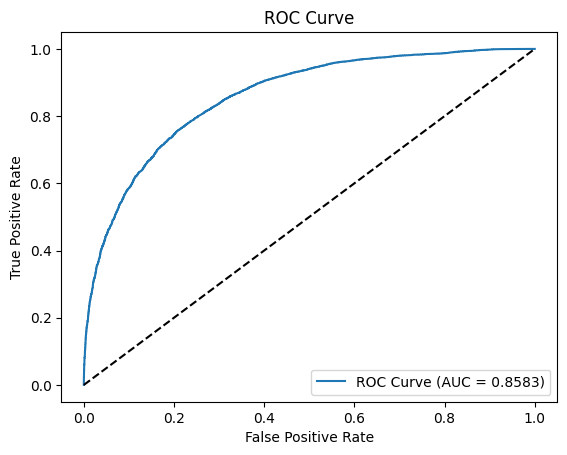

In [1]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv1D, GlobalMaxPooling1D, Dropout, Input
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert strings to array safely
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🔁 Step 6: Reshape for CNN input
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# 🧠 Step 7: CNN Model
model = Sequential([
    Input(shape=(X_train.shape[1], 1)),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 🚀 Step 8: Train the Model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=64)

# 📊 Step 9: Evaluate the Model
y_pred_prob = model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


Random Forest

In [2]:
# 📁 Create directory for saving results
import os
os.makedirs("cnn_results", exist_ok=True)

# ✅ Save Accuracy
with open("cnn_results/accuracy.txt", "w") as f:
    f.write(f"Accuracy: {acc:.4f}\n")

# ✅ Save Confusion Matrix
cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Pred 0", "Pred 1"])
cm_df.to_csv("cnn_results/confusion_matrix.csv")

# ✅ Save Classification Report
report = classification_report(y_test, y_pred, digits=4, output_dict=True)
pd.DataFrame(report).transpose().to_csv("cnn_results/classification_report.csv")

# ✅ Save Sensitivity & Specificity
with open("cnn_results/metrics.txt", "w") as f:
    f.write(f"Sensitivity (Recall): {sensitivity:.4f}\n")
    f.write(f"Specificity: {specificity:.4f}\n")
    f.write(f"AUC Score: {roc_auc:.4f}\n")

# ✅ Save ROC Curve Plot
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.savefig("cnn_results/roc_curve.png")
plt.close()

print("✅ All CNN evaluation results saved in: cnn_results/")


✅ All CNN evaluation results saved in: cnn_results/


✅ Accuracy: 0.9813684663986215


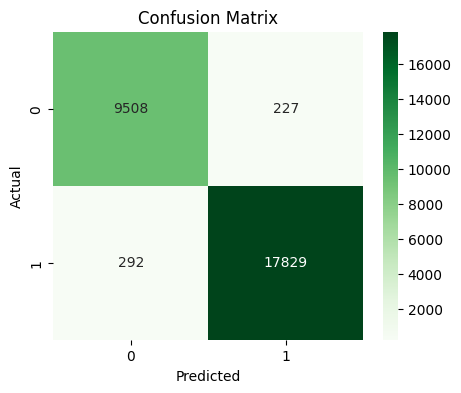


Classification Report:
               precision    recall  f1-score   support

           0     0.9702    0.9767    0.9734      9735
           1     0.9874    0.9839    0.9857     18121

    accuracy                         0.9814     27856
   macro avg     0.9788    0.9803    0.9795     27856
weighted avg     0.9814    0.9814    0.9814     27856

Sensitivity (Recall): 0.9839
Specificity: 0.9767


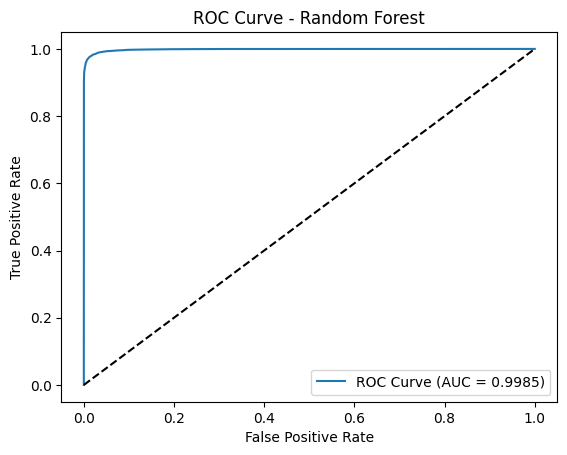

In [3]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = rf_model.predict(X_test)
y_pred_prob = rf_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.show()


In [4]:
# 📁 Create directory to store RF results
os.makedirs("rf_results", exist_ok=True)

# ✅ Save Accuracy
with open("rf_results/accuracy.txt", "w") as f:
    f.write(f"Accuracy: {acc:.4f}\n")

# ✅ Save Confusion Matrix
cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Pred 0", "Pred 1"])
cm_df.to_csv("rf_results/confusion_matrix.csv")

# ✅ Save Classification Report
report = classification_report(y_test, y_pred, digits=4, output_dict=True)
pd.DataFrame(report).transpose().to_csv("rf_results/classification_report.csv")

# ✅ Save Sensitivity & Specificity
with open("rf_results/metrics.txt", "w") as f:
    f.write(f"Sensitivity (Recall): {sensitivity:.4f}\n")
    f.write(f"Specificity: {specificity:.4f}\n")
    f.write(f"AUC Score: {roc_auc:.4f}\n")

# ✅ Save ROC Curve Plot
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend(loc='lower right')
plt.savefig("rf_results/roc_curve.png")
plt.close()

print("✅ All Random Forest evaluation results saved in: rf_results/")


✅ All Random Forest evaluation results saved in: rf_results/


Decision Tree

✅ Accuracy: 0.9667935094773119


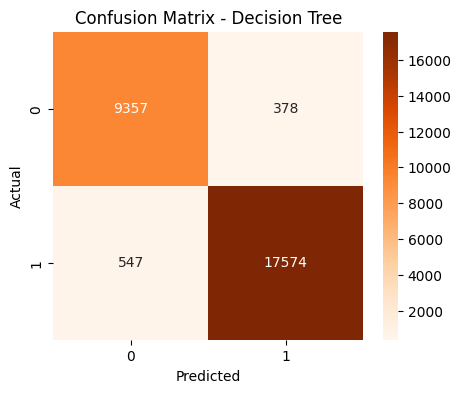


Classification Report:
               precision    recall  f1-score   support

           0     0.9448    0.9612    0.9529      9735
           1     0.9789    0.9698    0.9744     18121

    accuracy                         0.9668     27856
   macro avg     0.9619    0.9655    0.9636     27856
weighted avg     0.9670    0.9668    0.9669     27856

Sensitivity (Recall): 0.9698
Specificity: 0.9612


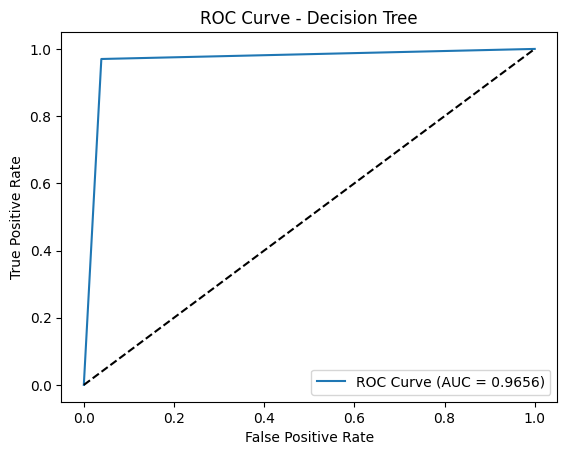

In [5]:
# 📦 Step 1: Import Libraries
import pandas as pd
import numpy as np
import ast
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 📂 Step 2: Load CSVs Without Header and Skip First Row
train_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_train.csv', header=None, skiprows=1)
val_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_val.csv', header=None, skiprows=1)
test_df = pd.read_csv('/kaggle/input/cyber-bullying-text-with-emojis/all_test.csv', header=None, skiprows=1)

# 📝 Step 3: Assign Column Names
column_names = ['text', 'features', 'level']
train_df.columns = column_names
val_df.columns = column_names
test_df.columns = column_names

# 🧹 Step 4: Remove invalid rows where 'features' is not a list
def is_valid_feature(row):
    try:
        parsed = ast.literal_eval(row)
        return isinstance(parsed, list)
    except:
        return False

train_df = train_df[train_df['features'].apply(is_valid_feature)]
val_df = val_df[val_df['features'].apply(is_valid_feature)]
test_df = test_df[test_df['features'].apply(is_valid_feature)]

# ✅ Step 5: Convert stringified feature vectors into NumPy arrays
def convert_str_to_array(column):
    return column.apply(lambda x: np.array(ast.literal_eval(x)))

X_train = np.stack(convert_str_to_array(train_df['features']))
y_train = train_df['level'].astype(int).values

X_val = np.stack(convert_str_to_array(val_df['features']))
y_val = val_df['level'].astype(int).values

X_test = np.stack(convert_str_to_array(test_df['features']))
y_test = test_df['level'].astype(int).values

# 🧠 Step 6: Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# 📊 Step 7: Evaluate the Model
y_pred = dt_model.predict(X_test)
y_pred_prob = dt_model.predict_proba(X_test)[:, 1]

# ✅ Accuracy
acc = accuracy_score(y_test, y_pred)
print("✅ Accuracy:", acc)

# ✅ Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ✅ Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred, digits=4))

# ✅ Sensitivity & Specificity
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")

# ✅ ROC Curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc = roc_auc_score(y_test, y_pred_prob)

plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.show()


In [6]:
import os

# Create output directory
os.makedirs('outputs_decision_tree', exist_ok=True)

# Save classification report to text file
with open('outputs_decision_tree/classification_report.txt', 'w') as f:
    f.write(f"Accuracy: {acc:.4f}\n")
    f.write(f"Sensitivity (Recall): {sensitivity:.4f}\n")
    f.write(f"Specificity: {specificity:.4f}\n\n")
    f.write("Classification Report:\n")
    f.write(classification_report(y_test, y_pred, digits=4))

# Save confusion matrix as image
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig('outputs_decision_tree/confusion_matrix.png')
plt.close()

# Save ROC curve
plt.figure()
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Decision Tree')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('outputs_decision_tree/roc_curve.png')
plt.close()
